# Product Review Text Preprocessing

- Author: Abdellah Boudlal
- Repository: https://github.com/Aboudlal/nlp-02-text-preprocessing-custom
- Date: 2026-10
- Purpose: Explore recurring vocabulary in headphone reviews.

## Analytical Question

Which words occur most frequently after preprocessing a small
collection of headphone reviews?

## Data Source

The dataset contains 12 fictional reviews generated with ChatGPT
for this educational project. Each line represents one review.
These examples are not real customer feedback and cannot support
conclusions about actual products or customer satisfaction.

## Methods

I apply tokenization, lowercasing, punctuation removal,
stop word filtering, and a minimum token length of three characters.

I exclude "headphones" and "product" as topic-specific stop words
to focus on vocabulary describing product features and experiences.

I retain "not" because removing negation could change the meaning
of negative reviews.


## Section 0. Intro to Jupyter Notebooks

This is a Markdown cell. 
Tips for Jupyter Notebooks:

- To run a cell, press **Ctrl+Enter** (or **Cmd+Enter** on Mac) after editing the cell.
- Change the type of a cell (e.g., to code or markdown) by looking in the lower edge of the cell interface.
- Rearrange cells by dragging and dropping cells.
- Use **File > Save as** to rename and save a notebook. 
- You must select a kernel (Python environment) for your notebook. In VS Code, click **Select Kernel** in the top-right corner of the notebook interface and choose the desired kernel from the dropdown menu. 
- Follow suggestions to install recommended extensions.
- Once installed, click Select Kernel / Python Environments and choose the Recommended `.venv` option created for the project. This creates a new kernel for the notebook to run code using the packages installed in the local `.venv`.

TODO: Delete this cell or make your own notes.

## Section 1. Setup and Imports

Imports and configuration appear once, at the top.

WHY:
- Keeps notebooks readable and reproducible
- Mirrors professional scripts
- Makes requirements clear

This is a Markdown cell.

In [1]:
# Section 1 Python cell.

# Imports at the top of the file
# REQ: External packages must be defined in pyproject.toml
# REQ: External packages must be installed in the environment using `uv sync` command
# REQ: External packages used in this notebook must be imported here

from pathlib import Path
import re

import matplotlib.pyplot as plt
import polars as pl

print("Imports complete.")

Imports complete.


## Section 2. Read the Text Data

This is a Markdown cell.

In [2]:
# Section 2 Python cell

# In notebooks, start with the current working directory
# where the notebook is located.
ROOT_PATH: Path = Path.cwd()

if not (ROOT_PATH / "data").is_dir():
    ROOT_PATH = ROOT_PATH.parent

DATA_PATH: Path = ROOT_PATH / "data"
NOTEBOOKS_PATH: Path = ROOT_PATH / "notebooks"
SCRIPTS_PATH: Path = ROOT_PATH / "scripts"

# Choose a text file to analyze.
# Each line is treated as one text record.
input_path: Path = DATA_PATH / "product_reviews.txt"

# Read all lines from the file.
text_list: list[str] = input_path.read_text(encoding="utf-8").splitlines()

# Remove blank lines.
text_list = [line.strip() for line in text_list if line.strip()]

print("Data loaded successfully.")
print(f"Loaded {len(text_list):,} text records.")

# Combine all text rows into one large string for simple preprocessing.
raw_text: str = " ".join(text_list)

print(f"Raw text length: {len(raw_text):,} characters")
print("First 500 characters of raw text:")
print(raw_text[:500])

Data loaded successfully.
Loaded 12 text records.
Raw text length: 664 characters
First 500 characters of raw text:
The headphones have clear sound and a comfortable fit. Battery life is excellent, but the headphones feel heavy. The sound is clear, but the battery does not last long. These headphones are comfortable for work and online classes. The microphone is clear, but the connection is not reliable. Battery life is good and charging is fast. The headphones are not comfortable after several hours. Sound quality is excellent and the connection is reliable. The microphone is not clear during calls. These he


## Section 3. Inspect the Raw Text

This is a Markdown cell.

In [3]:
# Section 3 Python cell

# Review the text records before preprocessing.
# This helps confirm the data loaded correctly and gives a
# sense of the structure of the text.

print("First 5 text records:")
for line in text_list[:5]:
    print("-", line)

print(f"\nLoaded {len(text_list):,} text records.")
print(f"Raw text length: {len(raw_text):,} characters")

print("\nFirst 500 characters of combined text:")
print(raw_text[:500])

First 5 text records:
- The headphones have clear sound and a comfortable fit.
- Battery life is excellent, but the headphones feel heavy.
- The sound is clear, but the battery does not last long.
- These headphones are comfortable for work and online classes.
- The microphone is clear, but the connection is not reliable.

Loaded 12 text records.
Raw text length: 664 characters

First 500 characters of combined text:
The headphones have clear sound and a comfortable fit. Battery life is excellent, but the headphones feel heavy. The sound is clear, but the battery does not last long. These headphones are comfortable for work and online classes. The microphone is clear, but the connection is not reliable. Battery life is good and charging is fast. The headphones are not comfortable after several hours. Sound quality is excellent and the connection is reliable. The microphone is not clear during calls. These he


## Section 4. Tokenize the Raw Text

This is a Markdown cell.

In [4]:
# Section 4 Python cell

# Split the raw text into rough word-like pieces using whitespace.
raw_tokens: list[str] = raw_text.split()
count_of_raw_tokens: int = len(raw_tokens)

print("First 20 raw tokens:")
print(raw_tokens[:20])
print(f"Total raw tokens: {count_of_raw_tokens:,}")

First 20 raw tokens:
['The', 'headphones', 'have', 'clear', 'sound', 'and', 'a', 'comfortable', 'fit.', 'Battery', 'life', 'is', 'excellent,', 'but', 'the', 'headphones', 'feel', 'heavy.', 'The', 'sound']
Total raw tokens: 107


## Section 5. Normalize the Text

This is a Markdown cell.

In [5]:
# Section 5 Python cell

# Convert all text to lowercase so words like "Data" and "data"
# are treated as the same token.
lower_text: str = raw_text.lower()

print("First 500 characters of lowercase text:")
print(lower_text[:500])

First 500 characters of lowercase text:
the headphones have clear sound and a comfortable fit. battery life is excellent, but the headphones feel heavy. the sound is clear, but the battery does not last long. these headphones are comfortable for work and online classes. the microphone is clear, but the connection is not reliable. battery life is good and charging is fast. the headphones are not comfortable after several hours. sound quality is excellent and the connection is reliable. the microphone is not clear during calls. these he


## Section 6. Remove Punctuation and Tokenize Again


This is a Markdown cell.

In [6]:
# Section 6 Python cell

# Replace any character that is not a letter, number, or whitespace
# with a space. This removes punctuation and many special characters.
no_punct_text: str = re.sub(r"[^a-z0-9\s]", " ", lower_text)

# Tokenize again after punctuation removal.
tokens_no_punct: list[str] = no_punct_text.split()
count_of_tokens_no_punct: int = len(tokens_no_punct)

print("First 20 tokens after lowercasing and punctuation removal:")
print(tokens_no_punct[:20])
print(f"Total tokens after punctuation removal: {count_of_tokens_no_punct:,}")

First 20 tokens after lowercasing and punctuation removal:
['the', 'headphones', 'have', 'clear', 'sound', 'and', 'a', 'comfortable', 'fit', 'battery', 'life', 'is', 'excellent', 'but', 'the', 'headphones', 'feel', 'heavy', 'the', 'sound']
Total tokens after punctuation removal: 107


## Section 7. Remove Stop Words


This is a Markdown cell.

In [7]:
# Section 7 Python cell

# Stop words are very common words that often add little meaning
# for simple frequency analysis.
STOP_WORDS: set[str] = {
    "a",
    "an",
    "and",
    "are",
    "as",
    "at",
    "be",
    "but",
    "by",
    "for",
    "from",
    "has",
    "have",
    "in",
    "is",
    "it",
    "its",
    "of",
    "on",
    "or",
    "that",
    "the",
    "to",
    "was",
    "were",
    "will",
    "with",
}

# Technical modification: exclude frequent topic words.
# Exclude topic words while retaining descriptive vocabulary.
STOP_WORDS.update({"headphones", "product"})

# Keep only tokens that:
# - are longer than 2 characters
# - are not in the stop word set
clean_tokens: list[str] = [
    token for token in tokens_no_punct if len(token) > 2 and token not in STOP_WORDS
]

count_of_clean_tokens: int = len(clean_tokens)

print("First 20 cleaned tokens:")
print(clean_tokens[:20])
print(f"Total cleaned tokens: {count_of_clean_tokens:,}")

First 20 cleaned tokens:
['clear', 'sound', 'comfortable', 'fit', 'battery', 'life', 'excellent', 'feel', 'heavy', 'sound', 'clear', 'battery', 'does', 'not', 'last', 'long', 'these', 'comfortable', 'work', 'online']
Total cleaned tokens: 59


## Section 8. Build a Before/After Summary Table


This is a Markdown cell.

In [8]:
# Section 8 Python cell

summary_df: pl.DataFrame = pl.DataFrame(
    {
        "stage": [
            "raw tokens",
            "after punctuation removal",
            "after stop word removal",
        ],
        "count": [
            count_of_raw_tokens,
            count_of_tokens_no_punct,
            count_of_clean_tokens,
        ],
    }
)

print("Preprocessing summary:")
print(summary_df)

Preprocessing summary:
shape: (3, 2)
┌───────────────────────────┬───────┐
│ stage                     ┆ count │
│ ---                       ┆ ---   │
│ str                       ┆ i64   │
╞═══════════════════════════╪═══════╡
│ raw tokens                ┆ 107   │
│ after punctuation removal ┆ 107   │
│ after stop word removal   ┆ 59    │
└───────────────────────────┴───────┘


## Section 9. Build a Frequency Table with Polars

This is a Markdown cell.

In [9]:
# Section 9 Python cell

# Create a Polars DataFrame with one row per cleaned token.
token_df: pl.DataFrame = pl.DataFrame({"token": clean_tokens})

# Group by token, count occurrences, and sort from most common to least common.
freq_df: pl.DataFrame = token_df.group_by("token").len().sort("len", descending=True)

print("Top 20 most frequent cleaned tokens:")
print(freq_df.head(20))

Top 20 most frequent cleaned tokens:
shape: (20, 2)
┌─────────────┬─────┐
│ token       ┆ len │
│ ---         ┆ --- │
│ str         ┆ u64 │
╞═════════════╪═════╡
│ not         ┆ 5   │
│ comfortable ┆ 4   │
│ sound       ┆ 4   │
│ battery     ┆ 4   │
│ clear       ┆ 4   │
│ …           ┆ …   │
│ after       ┆ 1   │
│ lightweight ┆ 1   │
│ classes     ┆ 1   │
│ last        ┆ 1   │
│ heavy       ┆ 1   │
└─────────────┴─────┘


## Section 10. Build a "Most Frequent Cleaned Tokens" Bar Chart


This is a Markdown cell.

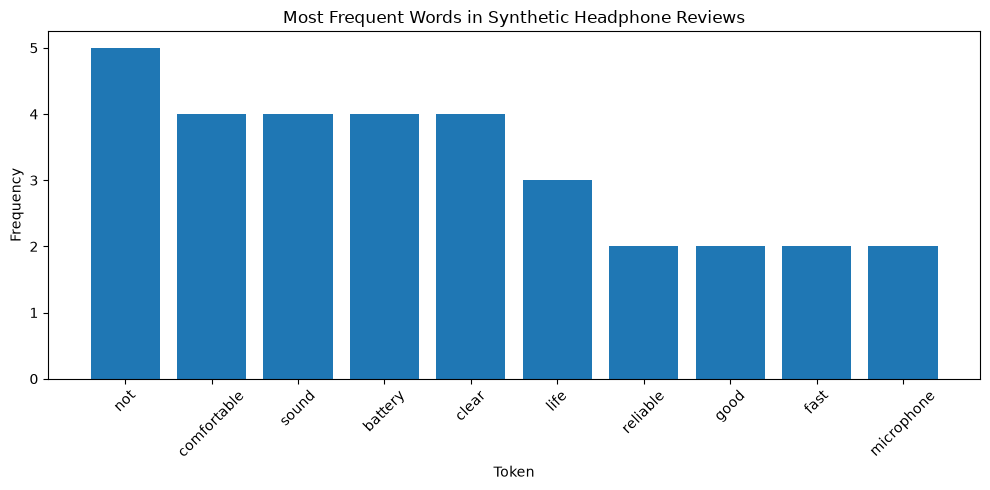

In [10]:
# Section 10 Python cell

top_df: pl.DataFrame = freq_df.head(10)

plt.figure(figsize=(10, 5))
plt.bar(top_df["token"], top_df["len"])

ax = plt.gca()
ax.tick_params(axis="x", labelrotation=45)

plt.title("Most Frequent Words in Synthetic Headphone Reviews")
plt.xlabel("Token")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

## Section 11. Compare Raw vs Clean Token Counts


This is a Markdown cell.

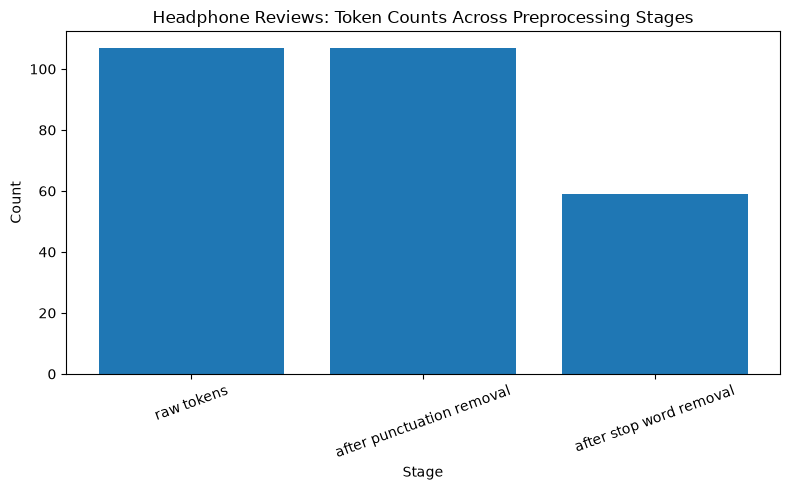

In [11]:
# Section 11 Python cell

plt.figure(figsize=(8, 5))
plt.bar(summary_df["stage"], summary_df["count"])

ax = plt.gca()
ax.tick_params(axis="x", labelrotation=20)

plt.title("Headphone Reviews: Token Counts Across Preprocessing Stages")
plt.xlabel("Stage")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

## Results and Interpretation

The dataset contains 12 fictional headphone reviews generated
with ChatGPT for this educational project.

### Preprocessing Results

- Raw tokens: 107.
- Tokens after punctuation removal: 107.
- Cleaned tokens: 59.
- Total reduction: 48 token occurrences.

Punctuation removal did not change the token count in this dataset.
Stop word filtering, topic-word filtering, and the minimum token
length reduced the count from 107 to 59.

### Frequent Words

The most frequent cleaned token is "not", with 5 occurrences.
"Sound", "clear", "battery", and "comfortable" each occur 4 times.

These words highlight recurring vocabulary related to sound,
battery performance, and comfort in the sample reviews.

### Analytical Insight

Retaining "not" is important because negation can change meaning.
For example, "comfortable" and "not comfortable" express different
opinions but both contribute to the count of "comfortable".

Removing "headphones" helps focus the frequency table on other
vocabulary. However, word frequencies alone cannot determine
whether a review is positive or negative.

### Limitations

The dataset is small and fictional. The findings describe these
12 examples only and cannot be generalized to real customers.

The analysis counts individual words and does not preserve their
relationships. Examining phrases would provide more context.